# Bank Marketing Analytics
## Análise exploratória dos dados de campanhas de marketing bancário

**Projeto de portfólio — Data Analytics**

Este notebook documenta o processo de análise do conjunto *Bank Marketing*. O objetivo é investigar como características dos clientes, informações sobre contatos anteriores, características da campanha e indicadores econômicos se relacionam com a adesão a depósitos a prazo.

A estrutura segue uma sequência analítica:

1. Bibliotecas e carregamento dos dados;
2. Conhecendo a base;
3. Preparação de variáveis;
4. Perfil dos clientes;
5. Duração das ligações;
6. Contatos anteriores;
7. Testes de associação entre variáveis categóricas;
8. Indicadores econômicos;
9. Correlação entre os indicadores econômicos;
10. Tamanho dos grupos e estabilidade das taxas;
11. Histórico e características da campanha;
12. Modelo exploratório de regressão logística;
13. Conclusões e limitações.

> **Importante:** os resultados apresentados descrevem associações nos dados. Eles não demonstram que uma característica ou condição econômica causou a adesão.

## 1. Bibliotecas e carregamento dos dados

A análise utiliza Pandas para manipulação dos dados, Matplotlib e Seaborn para visualização, SciPy para os testes estatísticos e scikit-learn para o modelo complementar.

A lógica de preparação e as funções de análise ficam em `src/bank_marketing_analysis.py` e são **as mesmas usadas por `main.py`**, de modo que o script e o notebook calculam sempre o mesmo resultado. O notebook importa essas funções em vez de reescrevê-las.

O arquivo CSV deve estar no diretório `data/`, com o nome `bank-additional-full.csv`. Execute o notebook a partir da raiz do projeto.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr

from src.bank_marketing_analysis import (
    ECONOMIC_INDICATORS,
    adherence_summary,
    calculate_adherence_rate,
    calculate_association,
    fit_logistic_model,
    load_data,
    prepare_data,
    reference_categories,
)

pd.set_option("display.max_columns", None)

DATA_PATH = "data/bank-additional-full.csv"

bank_campaign_df = load_data(DATA_PATH)

print(f"Quantidade de registros: {bank_campaign_df.shape[0]:,}")
print(f"Quantidade de colunas: {bank_campaign_df.shape[1]}")
bank_campaign_df.head()

Quantidade de registros: 41,188
Quantidade de colunas: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Conhecendo a base

A base contém informações demográficas dos clientes, dados dos contatos realizados durante as campanhas e indicadores do contexto econômico.

A variável de interesse é `y`:

- `yes`: o cliente aderiu ao depósito a prazo;
- `no`: o cliente não aderiu.

Antes de iniciar as comparações, é importante observar os tipos de dados, valores ausentes e a distribuição geral da variável-alvo.

In [2]:
bank_campaign_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [3]:
bank_campaign_df.isna().sum().sort_values(ascending=False)

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

### 2.1 Distribuição geral da adesão

A primeira pergunta é: **qual é a proporção de clientes que aderiram ao produto?**

Essa informação estabelece uma referência para interpretar as taxas encontradas nos demais grupos.

In [4]:
outcome_distribution = (
    bank_campaign_df["y"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percentage")
)

outcome_distribution.round(2)

y
no     88.73
yes    11.27
Name: percentage, dtype: float64

**Resultado observado:** aproximadamente 88,73% dos registros são `no` e 11,27% são `yes`.

Isso mostra que a classe positiva é minoritária. Portanto, ao comparar grupos, é mais informativo observar a taxa de adesão dentro de cada grupo do que olhar apenas para a quantidade absoluta de adesões.

## 3. Preparação de variáveis para a análise

Foram criadas variáveis agrupadas para facilitar a interpretação. Elas são geradas pela função `prepare_data`, a mesma usada no script principal.

In [5]:
bank_campaign_df = prepare_data(bank_campaign_df)

bank_campaign_df[
    ["age", "age_range", "duration", "duration_range",
     "previous", "previous_contacts_group", "pdays", "pdays_was_999",
     "job", "job_group"]
].head()

,age,age_range,duration,duration_range,previous,previous_contacts_group,pdays,pdays_was_999,job,job_group
0,56,Adulto,261,Longa,0,Não,999,True,housemaid,Operacional
1,57,Adulto,149,Média,0,Não,999,True,services,Operacional
2,37,Adulto,226,Longa,0,Não,999,True,services,Operacional
3,40,Adulto,151,Média,0,Não,999,True,admin.,Administrativo
4,56,Adulto,307,Longa,0,Não,999,True,services,Operacional


### Como interpretar os agrupamentos

- `duration_range`: separa as ligações em curtas, médias, longas e muito longas. A última faixa não possui limite superior fixo.
- `age_range`: separa os clientes em jovens (até 19 anos), adultos (20 a 60 anos) e idosos (61 anos ou mais).
- `previous_contacts_group`: distingue quem não tinha contatos anteriores (`previous == 0`) de quem tinha pelo menos um.
- `pdays_was_999`: indica `pdays == 999`, um código especial que significa "não contatado antes", e não 999 dias reais;
- `job_group`: reúne profissões em quatro grupos (`Administrativo`, `Técnico / negócios`, `Operacional` e `Outros`) para um teste complementar. O grupo `Outros` reúne `retired`, `student`, `unemployed` e `unknown`, ou seja, **não é homogêneo** e inclui as profissões de maior adesão.

**Atenção à classificação profissional:** esses grupos são uma simplificação exploratória criada para esta análise, não uma classificação ocupacional oficial. O grupo `Técnico / negócios`, por exemplo, reúne profissões técnicas e atividades empresariais/autônomas. Por isso, o resultado desse teste deve ser interpretado com cautela e não substitui a análise por profissão original.

Os agrupamentos simplificam a leitura, mas também reduzem detalhes. Observe sempre as quantidades de registros de cada grupo.

## 4. Perfil dos clientes

Nesta etapa, a pergunta é:

**As taxas de adesão variam entre grupos de clientes com diferentes características?**

Serão comparadas as taxas por estado civil, escolaridade, profissão e faixa etária. A taxa de adesão é calculada como a proporção de registros `yes` dentro de cada grupo.

In [6]:
marital_adherence = (
    bank_campaign_df.groupby("marital")["y"]
    .apply(calculate_adherence_rate)
    .sort_values(ascending=False)
)

education_adherence = (
    bank_campaign_df.groupby("education")["y"]
    .apply(calculate_adherence_rate)
    .sort_values(ascending=False)
)

job_adherence = (
    bank_campaign_df.groupby("job")["y"]
    .apply(calculate_adherence_rate)
    .sort_values(ascending=False)
)

age_adherence = (
    pd.crosstab(
        bank_campaign_df["age_range"],
        bank_campaign_df["y"],
        normalize="index"
    ) * 100
)

print("Adesão por estado civil (%)")
display(marital_adherence.round(2))

print("Adesão por escolaridade (%)")
display(education_adherence.round(2))

print("Adesão por profissão (%)")
display(job_adherence.round(2))

print("Distribuição percentual por faixa etária (%)")
display(age_adherence.round(2))

Adesão por estado civil (%)


marital
unknown     15.00
single      14.00
divorced    10.32
married     10.16
Name: y, dtype: float64

Adesão por escolaridade (%)


education
illiterate             22.22
unknown                14.50
university.degree      13.72
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.20
basic.9y                7.82
Name: y, dtype: float64

Adesão por profissão (%)


job
student          31.43
retired          25.23
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.89
Name: y, dtype: float64

Distribuição percentual por faixa etária (%)


y,no,yes
age_range,,
Jovem,54.67,45.33
Adulto,89.57,10.43
Idoso,54.51,45.49


### Interpretação

Na saída da execução consolidada, as maiores taxas por profissão foram observadas entre `student` (31,43%) e `retired` (25,23%). A menor taxa entre as categorias listadas foi a de `blue-collar` (6,89%).

A tabela de faixa etária apresenta a distribuição percentual de `no` e `yes` dentro de cada grupo. Ela complementa o teste qui-quadrado da seção 7.1: a tabela mostra **como** as taxas diferem, enquanto o teste avalia a evidência estatística de associação.

É importante diferenciar **taxa de adesão** de **quantidade de adesões**. Uma categoria numerosa pode concentrar mais adesões em quantidade absoluta mesmo sem apresentar a maior taxa percentual.


### 4.1 Gráfico — taxa de adesão por profissão

O gráfico de barras permite comparar as taxas percentuais entre profissões. A altura de cada barra representa a taxa de adesão dentro daquela categoria.

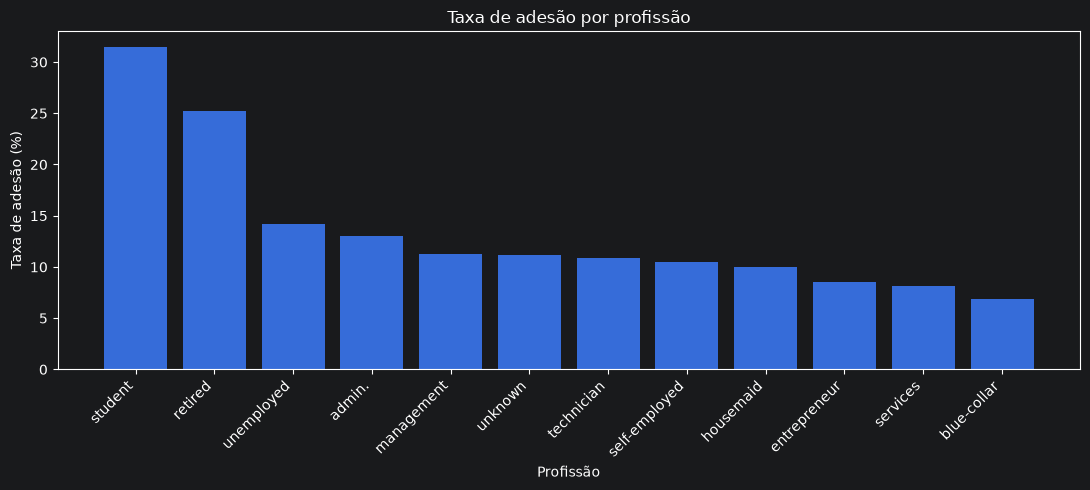

In [7]:
plt.figure(figsize=(11, 5))
plt.bar(job_adherence.index, job_adherence.values)
plt.title("Taxa de adesão por profissão")
plt.xlabel("Profissão")
plt.ylabel("Taxa de adesão (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 4.2 Faixa etária e profissão

A análise também compara a taxa de adesão considerando duas características simultaneamente: faixa etária e profissão.

A tabela de taxas deve ser observada junto com a tabela de quantidade de registros. Percentuais calculados sobre grupos muito pequenos podem variar bastante e não devem ser interpretados como padrões sólidos.


In [8]:
age_job_adherence = (
    bank_campaign_df
    .groupby(["age_range", "job"], observed=True)["y"]
    .apply(calculate_adherence_rate)
    .unstack()
)

age_job_counts = (
    bank_campaign_df
    .groupby(["age_range", "job"], observed=True)
    .size()
    .unstack()
)

print("Taxa de adesão por faixa etária e profissão (%)")
display(age_job_adherence.round(2))

print("Quantidade de registros por faixa etária e profissão")
display(age_job_counts)

Taxa de adesão por faixa etária e profissão (%)


job,admin.,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed,unknown
age_range,,,,,,,,,,,,
Jovem,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.33,NaN,NaN,NaN
Adulto,12.79,6.86,8.22,7.85,10.71,11.61,10.55,8.14,30.12,10.70,14.20,9.39
Idoso,53.19,25.00,62.50,50.00,60.00,46.17,0.00,0.00,NaN,35.29,14.29,38.10


Quantidade de registros por faixa etária e profissão


job,admin.,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed,unknown
age_range,,,,,,,,,,,,
Jovem,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.0,NaN,NaN,NaN
Adulto,10375.0,9234.0,1448.0,1006.0,2894.0,1042.0,1412.0,3967.0,800.0,6709.0,1007.0,309.0
Idoso,47.0,20.0,8.0,54.0,30.0,678.0,9.0,2.0,NaN,34.0,7.0,21.0


**Ponto de atenção:** algumas combinações possuem poucos registros. Por exemplo, determinadas profissões na faixa `Idoso` aparecem com quantidades muito pequenas. Uma taxa alta nesse cenário não significa necessariamente que exista um padrão confiável para toda a população.

## 5. Duração das ligações

Pergunta: **a duração das ligações apresenta diferenças entre os clientes que aderiram e os que não aderiram?**

Primeiro, comparamos média e mediana. A mediana ajuda a reduzir a influência de ligações excepcionalmente longas.

In [9]:
duration_summary = (
    bank_campaign_df.groupby("y")["duration"]
    .agg(["mean", "median"])
)

duration_summary.round(2)

,mean,median
y,,
no,220.84,163.5
yes,553.19,449.0


Na execução registrada, a duração média foi de aproximadamente **220,84 segundos** para `no` e **553,19 segundos** para `yes`. As medianas foram, respectivamente, **163,5** e **449 segundos**.

Os dois grupos apresentam uma diferença descritiva expressiva. Isso indica associação entre duração e resultado da ligação, mas não prova que prolongar uma ligação cause adesão.

### 5.1 Gráfico — distribuição da duração

O boxplot permite observar a dispersão e a assimetria da duração. O código abaixo oculta os pontos extremos (`showfliers=False`) para facilitar a visualização da parte central da distribuição.

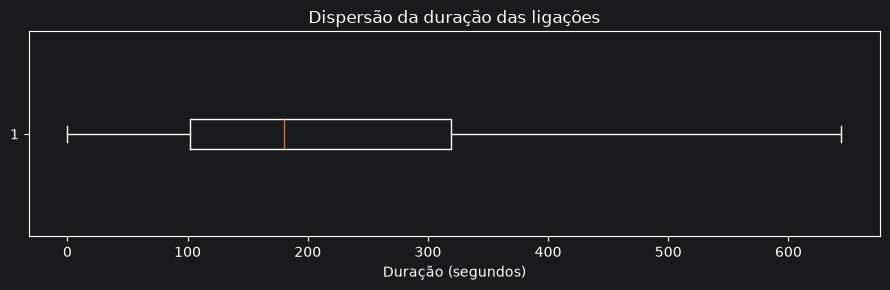

In [10]:
plt.figure(figsize=(9, 3))
plt.boxplot(
    bank_campaign_df["duration"],
    orientation="horizontal",
    showfliers=False
)
plt.title("Dispersão da duração das ligações")
plt.xlabel("Duração (segundos)")
plt.tight_layout()
plt.show()

### 5.2 Taxa de adesão por faixa de duração

As faixas permitem observar como a taxa de adesão varia conforme a duração registrada.

In [11]:
duration_adherence = (
    bank_campaign_df
    .groupby("duration_range", observed=True)["y"]
    .apply(calculate_adherence_rate)
)

duration_adherence.round(2)

duration_range
Curta           0.02
Média           3.43
Longa          14.05
Muito longa    48.61
Name: y, dtype: float64

Na execução registrada, as taxas foram aproximadamente:

- `Curta`: 0,02%;
- `Média`: 3,43%;
- `Longa`: 14,05%;
- `Muito longa`: 48,61%.

A taxa observada cresce conforme a faixa de duração aumenta. Entretanto, **duration é uma variável conhecida somente depois que a ligação termina**. Portanto, ela não estaria disponível para selecionar previamente quais clientes devem ser contatados. Em um modelo de previsão feito antes da ligação, usar essa variável também poderia gerar vazamento de informação (*data leakage*).

### 5.3 Gráfico — adesão por faixa de duração

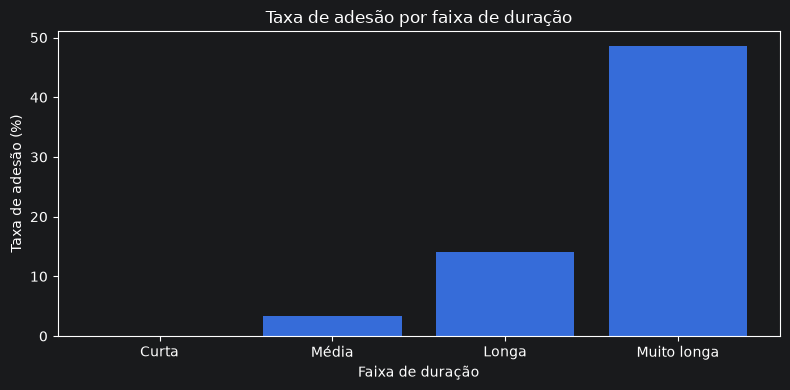

In [12]:
plt.figure(figsize=(8, 4))
plt.bar(duration_adherence.index.astype(str), duration_adherence.values)
plt.title("Taxa de adesão por faixa de duração")
plt.xlabel("Faixa de duração")
plt.ylabel("Taxa de adesão (%)")
plt.tight_layout()
plt.show()

## 6. Contatos anteriores

Pergunta: **clientes que já haviam sido contatados anteriormente apresentam uma taxa de adesão diferente?**

A coluna `previous` informa o número de contatos realizados antes desta campanha. Ela não deve ser interpretada automaticamente como número de campanhas distintas.

In [13]:
previous_contacts_table = pd.crosstab(
    bank_campaign_df["previous_contacts_group"],
    bank_campaign_df["y"]
)

previous_contacts_rate = (
    pd.crosstab(
        bank_campaign_df["previous_contacts_group"],
        bank_campaign_df["y"],
        normalize="index"
    ) * 100
)

print("Tabela de contingência")
display(previous_contacts_table)

print("Distribuição percentual dentro de cada grupo")
display(previous_contacts_rate.round(2))

Tabela de contingência


y,no,yes
previous_contacts_group,,
Não,32422,3141
Sim,4126,1499


Distribuição percentual dentro de cada grupo


y,no,yes
previous_contacts_group,,
Não,91.17,8.83
Sim,73.35,26.65


Na execução registrada:

- Sem contatos anteriores (`Não`): aproximadamente **8,83%** de adesão;
- Com pelo menos um contato anterior (`Sim`): aproximadamente **26,65%** de adesão.

A taxa foi maior no grupo com contatos anteriores. Isso é uma associação observada na base e não permite concluir que os contatos anteriores, isoladamente, causaram a adesão.

## 7. Testes de associação entre variáveis categóricas

As tabelas e os gráficos descrevem diferenças. Para avaliar se existe evidência estatística de associação entre duas variáveis categóricas, foi utilizado o teste qui-quadrado de independência.

Também foi calculado o **V de Cramér**, uma medida da intensidade da associação.

- O qui-quadrado e o valor-p ajudam a avaliar evidência contra a hipótese de independência.
- O V de Cramér varia de 0 a 1 e descreve a intensidade da associação.
- Um valor-p pequeno não significa, por si só, que a associação seja forte ou importante na prática.
A função `calculate_association` (em `src/bank_marketing_analysis.py`) executa o teste, calcula o V de Cramér e imprime o resultado.

### 7.1 Faixa etária × adesão

In [14]:
age_contingency = pd.crosstab(
    bank_campaign_df["age_range"],
    bank_campaign_df["y"]
)

age_test = calculate_association(age_contingency, "Faixa etária e adesão")

Análise: Faixa etária e adesão
Qui-quadrado: 1181.9202
Valor-p: 2.23509e-257
Graus de liberdade: 2
V de Cramér: 0.1694
Menor frequência esperada: 8.4491
Células com frequência esperada < 5: 0



Na execução registrada, o teste apresentou qui-quadrado de aproximadamente **1181,9202**, valor-p muito pequeno (`p < 0,001`) e V de Cramér de **0,1694**. Há evidência estatística de associação, mas a intensidade medida pelo V de Cramér é relativamente modesta.

### 7.2 Profissão × adesão

In [15]:
job_contingency = pd.crosstab(
    bank_campaign_df["job"],
    bank_campaign_df["y"]
)

job_test = calculate_association(job_contingency, "Profissão e adesão")

Análise: Profissão e adesão
Qui-quadrado: 961.2424
Valor-p: 4.18976e-199
Graus de liberdade: 11
V de Cramér: 0.1528
Menor frequência esperada: 37.1759
Células com frequência esperada < 5: 0



Resultado registrado: qui-quadrado de **961,2424**, `p < 0,001` e V de Cramér de **0,1528**. Existe evidência estatística de associação entre profissão e adesão, com intensidade relativamente modesta.

### 7.3 Contatos anteriores × adesão

In [16]:
previous_test = calculate_association(
    previous_contacts_table,
    "Contatos anteriores e adesão"
)

Análise: Contatos anteriores e adesão
Qui-quadrado: 1540.4987
Valor-p: 0
Graus de liberdade: 1
V de Cramér: 0.1935
Menor frequência esperada: 633.6797
Células com frequência esperada < 5: 0



Resultado registrado: qui-quadrado de **1540,4987**, `p < 0,001` e V de Cramér de **0,1935**. Há evidência estatística de associação, com intensidade ainda relativamente modesta.

### 7.4 Faixa etária + profissão × adesão

O cruzamento detalhado considera cada combinação de faixa etária e profissão.

In [17]:
age_job_contingency = pd.crosstab(
    [bank_campaign_df["age_range"], bank_campaign_df["job"]],
    bank_campaign_df["y"]
)

age_job_test = calculate_association(
    age_job_contingency,
    "Faixa etária e profissão com adesão"
)

Análise: Faixa etária e profissão com adesão
Qui-quadrado: 1775.1359
Valor-p: 0
Graus de liberdade: 23
V de Cramér: 0.2076
Menor frequência esperada: 0.2253
Células com frequência esperada < 5: 9
Atenção: há frequências esperadas abaixo de 5; interprete o teste com cautela.



Na execução registrada, o V de Cramér foi **0,2076**, mas 9 frequências esperadas ficaram abaixo de 5 e a menor foi aproximadamente 0,2253. Isso exige cautela: a aproximação do qui-quadrado pode não ser adequada para esse cruzamento detalhado.

### 7.5 Faixa etária + grupos de profissão × adesão

Para reduzir a quantidade de categorias, as profissões foram reunidas em quatro grupos: `Administrativo`, `Técnico / negócios`, `Operacional` e `Outros`.

O agrupamento é pragmático, não uma taxonomia oficial. `Técnico / negócios` reúne `technician`, `entrepreneur` e `self-employed`; essas categorias não são homogêneas. A análise agrupada serve como complemento exploratório, enquanto a análise por profissão original preserva mais detalhes.

In [18]:
age_job_group_contingency = pd.crosstab(
    [bank_campaign_df["age_range"], bank_campaign_df["job_group"]],
    bank_campaign_df["y"]
)

age_job_group_test = calculate_association(
    age_job_group_contingency,
    "Faixa etária e grupos de profissão com adesão"
)

Análise: Faixa etária e grupos de profissão com adesão
Qui-quadrado: 1520.2165
Valor-p: 0
Graus de liberdade: 8
V de Cramér: 0.1921
Menor frequência esperada: 5.7454
Células com frequência esperada < 5: 0



Resultado registrado: qui-quadrado de **1520,2165**, `p < 0,001`, V de Cramér de **0,1921** e nenhuma frequência esperada abaixo de 5 (mínimo aproximado de 5,7454).

Nesse agrupamento, não foram observadas frequências esperadas abaixo de 5. Isso melhora a condição de aplicação do teste, mas não torna a classificação profissional necessariamente mais adequada. Ainda assim, esse teste avalia a associação conjunta entre as categorias combinadas e a adesão; ele não demonstra, por si só, que a idade modifica o efeito da profissão.

### 7.6 Grupos de profissão × adesão (sem faixa etária)

Teste complementar usando apenas `job_group`, sem combinar com a faixa etária. Vale a mesma ressalva: o agrupamento é exploratório e o grupo `Outros` reúne profissões muito diferentes entre si (aposentados, estudantes, desempregados e `unknown`).

In [19]:
job_group_contingency = pd.crosstab(
    bank_campaign_df["job_group"],
    bank_campaign_df["y"]
)

job_group_test = calculate_association(
    job_group_contingency,
    "Grupos de profissão e adesão"
)

Análise: Grupos de profissão e adesão
Qui-quadrado: 741.6679
Valor-p: 1.93415e-160
Graus de liberdade: 3
V de Cramér: 0.1342
Menor frequência esperada: 443.7448
Células com frequência esperada < 5: 0



Leia o V de Cramér e as frequências esperadas diretamente na saída acima. Os valores não foram fixados neste texto para não ficarem desatualizados quando o notebook for executado novamente.

### Resumo dos testes categóricos

| Cruzamento | V de Cramér | Observação |
|---|---:|---|
| Faixa etária × adesão | 0,1694 | Associação estatística; intensidade modesta |
| Profissão × adesão | 0,1528 | Associação estatística; intensidade modesta |
| Contatos anteriores × adesão | 0,1935 | Associação estatística; intensidade modesta |
| Faixa etária + profissão × adesão | 0,2076 | Frequências esperadas baixas; cautela |
| Faixa etária + grupos de profissão × adesão | 0,1921 | Sem frequências esperadas abaixo de 5 |

O cruzamento da seção 7.6 (apenas grupos de profissão) não está na tabela: leia seu resultado diretamente da saída da célula correspondente.

Os valores acima correspondem à execução registrada do script. Ao executar novamente o notebook, use os resultados calculados nas células como referência atualizada.

## 8. Indicadores econômicos

Nesta etapa, a pergunta é:

**Como a taxa de adesão varia conforme os indicadores econômicos registrados na base?**

Foram explorados cinco indicadores:

| Coluna | Descrição |
|---|---|
| `emp.var.rate` | Taxa de variação do emprego |
| `cons.price.idx` | Índice de preços ao consumidor |
| `cons.conf.idx` | Índice de confiança do consumidor |
| `euribor3m` | Taxa Euribor de três meses |
| `nr.employed` | Número de pessoas empregadas |

Para cada indicador, os registros foram agrupados por valor distinto. Em seguida, foi calculada a quantidade de registros e a taxa de adesão de cada grupo.

In [20]:
economic_tables = {}
economic_results = []

for column, indicator_name in ECONOMIC_INDICATORS.items():
    grouped_data = bank_campaign_df.groupby(column).agg(
        total_records=("y", "count"),
        adherence_rate=("y", calculate_adherence_rate)
    )

    economic_tables[column] = grouped_data

    rho, p_value = spearmanr(
        grouped_data.index,
        grouped_data["adherence_rate"]
    )

    economic_results.append({
        "indicator": column,
        "spearman_rho": rho,
        "p_value": p_value,
        "distinct_values": len(grouped_data)
    })

    print(indicator_name)
    display(grouped_data.round(2))

economic_results_df = pd.DataFrame(economic_results)
economic_results_df

Taxa de variação do emprego


,total_records,adherence_rate
emp.var.rate,,
-3.4,1071,42.39
-3.0,172,51.16
-2.9,1663,35.72
-1.8,9184,15.91
-1.7,773,52.13
-1.1,635,47.40
-0.2,10,10.00
-0.1,3683,6.30
1.1,7763,3.09


Índice de preços ao consumidor


,total_records,adherence_rate
cons.price.idx,,
92.201,770,34.29
92.379,267,39.70
92.431,447,40.27
92.469,178,37.08
92.649,357,47.06
92.713,172,51.16
92.756,10,10.00
92.843,282,44.68
92.893,5794,9.04


Índice de confiança do consumidor


,total_records,adherence_rate
cons.conf.idx,,
-50.8,128,45.31
-50.0,282,44.68
-49.5,204,45.59
-47.1,2458,17.98
-46.2,5794,9.04
-45.9,10,10.00
-42.7,6685,6.09
-42.0,3616,5.25
-41.8,4374,4.30


Taxa Euribor de 3 meses


,total_records,adherence_rate
euribor3m,,
0.634,8,75.00
0.635,43,51.16
0.636,14,21.43
0.637,6,83.33
0.638,7,71.43
...,...,...
4.967,643,5.13
4.968,992,5.75
4.970,172,2.33


Número de pessoas empregadas


,total_records,adherence_rate
nr.employed,,
4963.6,635,47.40
4991.6,773,52.13
5008.7,650,56.77
5017.5,1071,42.39
5023.5,172,51.16
5076.2,1663,35.72
5099.1,8534,12.80
5176.3,10,10.00
5191.0,7763,3.09


,indicator,spearman_rho,p_value,distinct_values
0,emp.var.rate,-0.733333,1.580060e-02,10
1,cons.price.idx,0.160342,4.339447e-01,26
2,cons.conf.idx,0.205470,3.139512e-01,26
3,euribor3m,-0.425325,2.583353e-15,316
4,nr.employed,-0.890909,2.334582e-04,11


### 8.1 Correlação de Spearman

A correlação de Spearman mede a direção e a intensidade de uma relação monotônica entre duas variáveis. Neste projeto, ela foi calculada entre:

- os valores distintos de cada indicador econômico;
- a taxa de adesão agrupada correspondente a cada valor.

Interpretação geral do coeficiente:

- próximo de `+1`: associação monotônica positiva forte;
- próximo de `-1`: associação monotônica negativa forte;
- próximo de `0`: pouca evidência de relação monotônica.

Os resultados registrados foram:

In [21]:
economic_results_df.round(6)

,indicator,spearman_rho,p_value,distinct_values
0,emp.var.rate,-0.733333,0.015801,10
1,cons.price.idx,0.160342,0.433945,26
2,cons.conf.idx,0.205470,0.313951,26
3,euribor3m,-0.425325,0.000000,316
4,nr.employed,-0.890909,0.000233,11


| Indicador | Spearman (ρ) | Valor-p registrado | Valores distintos |
|---|---:|---:|---:|
| `emp.var.rate` | -0,7333 | 0,0158 | 10 |
| `cons.price.idx` | 0,1603 | 0,4339 | 26 |
| `cons.conf.idx` | 0,2055 | 0,3140 | 26 |
| `euribor3m` | -0,4253 | 2,58335e-15 | 316 |
| `nr.employed` | -0,8909 | 0,000233 | 11 |

`emp.var.rate` e `nr.employed` apresentaram associações monotônicas negativas fortes na análise agrupada. `euribor3m` apresentou associação negativa moderada. Para `cons.price.idx` e `cons.conf.idx`, as correlações foram positivas e fracas, sem evidência estatística pelos valores-p calculados nessa exploração.

### 8.2 Gráficos de dispersão dos indicadores

Os gráficos abaixo mostram cada valor do indicador no eixo horizontal e a taxa de adesão correspondente no eixo vertical. Cada ponto representa um valor distinto do indicador, não um cliente individual.

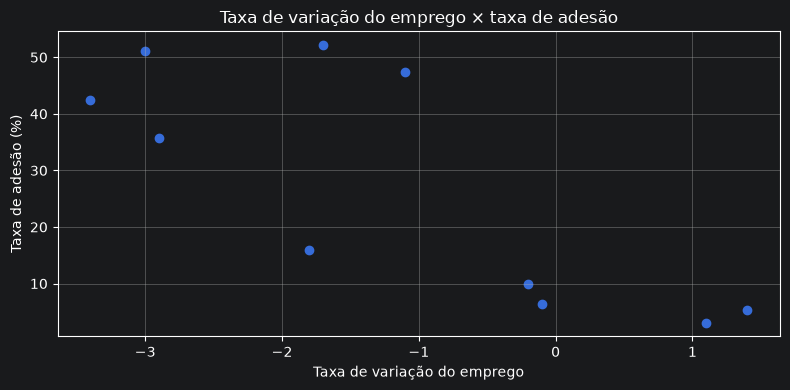

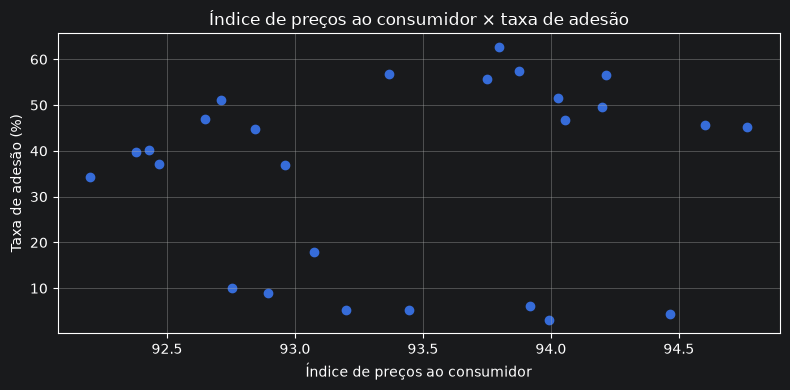

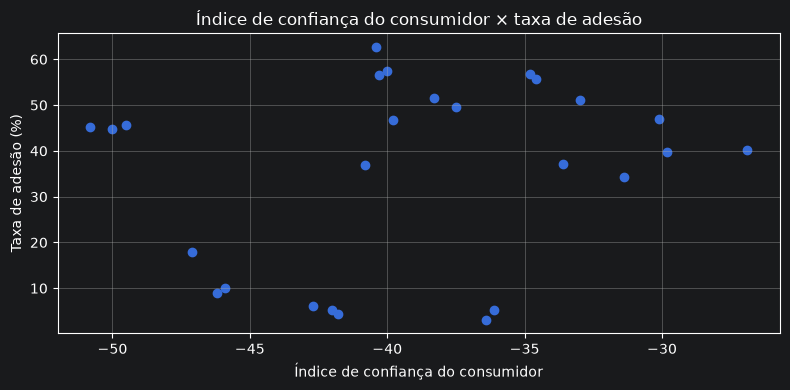

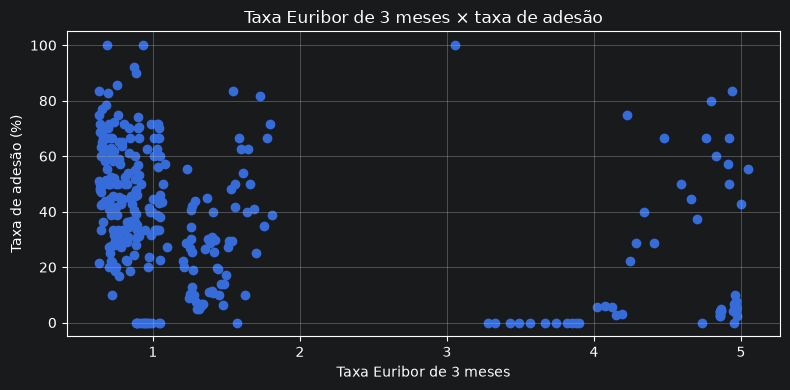

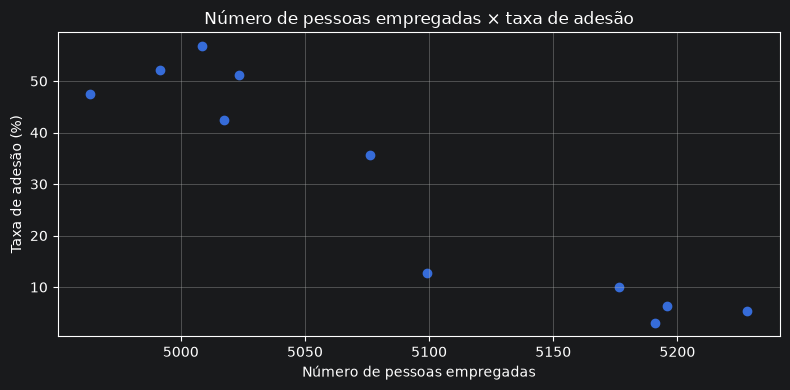

In [22]:
for column, indicator_name in ECONOMIC_INDICATORS.items():
    grouped_data = economic_tables[column]

    plt.figure(figsize=(8, 4))
    plt.scatter(
        grouped_data.index,
        grouped_data["adherence_rate"]
    )
    plt.title(f"{indicator_name} × taxa de adesão")
    plt.xlabel(indicator_name)
    plt.ylabel("Taxa de adesão (%)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Limitação importante da análise econômica

Os indicadores econômicos são compartilhados por vários registros de clientes e se repetem em diferentes linhas. O cálculo de Spearman foi realizado sobre os valores distintos de cada indicador e suas taxas agrupadas. Assim:

- a quantidade de observações estatísticas é o número de valores distintos, não os 41.188 clientes;
- cada valor distinto recebe o mesmo peso na correlação, mesmo que tenha quantidades diferentes de clientes;
- taxas calculadas com poucos registros podem ser instáveis;
- os valores-p devem ser tratados como exploratórios, e não como evidência inferencial definitiva.

Essa limitação é especialmente importante para `euribor3m`, que possui muitos valores distintos, alguns deles com pouquíssimos registros.

## 9. Correlação entre os indicadores econômicos

Também foi calculada uma matriz de correlação de Pearson entre os cinco indicadores. O objetivo é observar quais indicadores apresentam movimentos lineares semelhantes na base.

In [23]:
economic_data = bank_campaign_df[list(ECONOMIC_INDICATORS.keys())]

economic_correlation_matrix = economic_data.corr(method="pearson")

economic_correlation_matrix.round(4)

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.0000,0.7753,0.1960,0.9722,0.9070
cons.price.idx,0.7753,1.0000,0.0590,0.6882,0.5220
cons.conf.idx,0.1960,0.0590,1.0000,0.2777,0.1005
euribor3m,0.9722,0.6882,0.2777,1.0000,0.9452
nr.employed,0.9070,0.5220,0.1005,0.9452,1.0000


Na execução registrada, algumas correlações positivas foram elevadas:

- `emp.var.rate` × `euribor3m`: aproximadamente **0,9722**;
- `euribor3m` × `nr.employed`: aproximadamente **0,9452**;
- `emp.var.rate` × `nr.employed`: aproximadamente **0,9070**;
- `emp.var.rate` × `cons.price.idx`: aproximadamente **0,7753**.

Já `cons.conf.idx` apresentou correlações mais fracas com os demais indicadores.

Esses resultados sugerem que alguns indicadores acompanham movimentos econômicos semelhantes. Portanto, não é adequado interpretá-los automaticamente como fatores independentes.

### 9.1 Mapa de calor da correlação

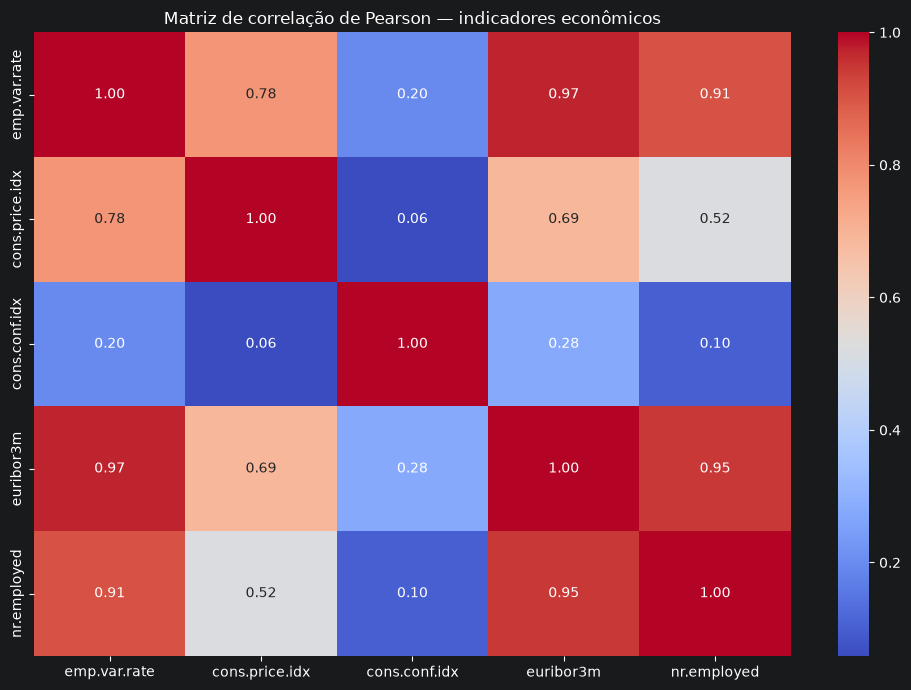

In [24]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    economic_correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Matriz de correlação de Pearson — indicadores econômicos")
plt.tight_layout()
plt.show()

**Limitação:** essa matriz foi calculada sobre os registros de clientes, nos quais os valores dos indicadores econômicos se repetem. Ela é uma descrição das correlações na base, não uma análise com 41.188 observações econômicas independentes.

## 10. Tamanho dos grupos e estabilidade das taxas

Uma taxa percentual isolada pode parecer alta quando foi calculada com poucos registros. Por isso, as tabelas abaixo mostram também o tamanho de cada grupo (`n`). Grupos pequenos devem ser interpretados com cautela; intervalos de confiança podem ser adicionados em uma etapa posterior.

In [25]:
for column in ["marital", "education", "job", "age_range"]:
    print(f"\n--- {column} ---")
    display(adherence_summary(bank_campaign_df, column).round(2))


--- marital ---


,total,adesoes,taxa_adesao_pct
marital,,,
unknown,80,12,15.00
single,11568,1620,14.00
divorced,4612,476,10.32
married,24928,2532,10.16



--- education ---


,total,adesoes,taxa_adesao_pct
education,,,
illiterate,18,4,22.22
unknown,1731,251,14.50
university.degree,12168,1670,13.72
professional.course,5243,595,11.35
high.school,9515,1031,10.84
basic.4y,4176,428,10.25
basic.6y,2292,188,8.20
basic.9y,6045,473,7.82



--- job ---


,total,adesoes,taxa_adesao_pct
job,,,
student,875,275,31.43
retired,1720,434,25.23
unemployed,1014,144,14.20
admin.,10422,1352,12.97
management,2924,328,11.22
unknown,330,37,11.21
technician,6743,730,10.83
self-employed,1421,149,10.49
housemaid,1060,106,10.00



--- age_range ---


,total,adesoes,taxa_adesao_pct
age_range,,,
Idoso,910,414,45.49
Jovem,75,34,45.33
Adulto,40203,4192,10.43


A faixa `Jovem` contém somente 75 registros e, nesta base, todos são estudantes. Assim, a taxa elevada desse grupo não pode ser atribuída apenas à idade: idade e profissão estão confundidas nessa parte da amostra. O mesmo cuidado vale para categorias raras de escolaridade e estado civil.

## 11. Histórico e características da campanha

Além de `previous`, que conta contatos anteriores, `poutcome` registra o resultado da campanha anterior. `pdays` representa os dias desde o contato anterior; o valor 999 é um código especial que indica que o cliente não foi previamente contatado na campanha anterior. Também serão observados o canal de contato, o mês e o número de contatos na campanha atual.

In [26]:
for column in ["poutcome", "contact", "month", "pdays_was_999"]:
    print(f"\n--- Taxa de adesão por {column} ---")
    display(adherence_summary(bank_campaign_df, column).round(2))

print("\n--- Taxa de adesão por número de contatos na campanha (contatos 1 a 15) ---")
display(adherence_summary(bank_campaign_df, "campaign", sort_by_rate=False).head(15).round(2))


--- Taxa de adesão por poutcome ---


,total,adesoes,taxa_adesao_pct
poutcome,,,
success,1373,894,65.11
failure,4252,605,14.23
nonexistent,35563,3141,8.83



--- Taxa de adesão por contact ---


,total,adesoes,taxa_adesao_pct
contact,,,
cellular,26144,3853,14.74
telephone,15044,787,5.23



--- Taxa de adesão por month ---


,total,adesoes,taxa_adesao_pct
month,,,
mar,546,276,50.55
dec,182,89,48.90
sep,570,256,44.91
oct,718,315,43.87
apr,2632,539,20.48
aug,6178,655,10.60
jun,5318,559,10.51
nov,4101,416,10.14
jul,7174,649,9.05



--- Taxa de adesão por pdays_was_999 ---


,total,adesoes,taxa_adesao_pct
pdays_was_999,,,
False,1515,967,63.83
True,39673,3673,9.26



--- Taxa de adesão por número de contatos na campanha (contatos 1 a 15) ---


,total,adesoes,taxa_adesao_pct
campaign,,,
1,17642,2300,13.04
2,10570,1211,11.46
3,5341,574,10.75
4,2651,249,9.39
5,1599,120,7.50
6,979,75,7.66
7,629,38,6.04
8,400,17,4.25
9,283,17,6.01


`campaign` é o número de contatos realizados durante a campanha atual. `pdays=999` deve ser tratado como código especial, não como 999 dias reais. As diferenças observadas são descritivas e não demonstram causalidade.

**Resultados observados na execução:**

- Clientes com sucesso na campanha anterior (`poutcome = success`) aderiram a **65,11%**, contra **8,83%** entre os sem histórico anterior (`nonexistent`).
- Ligações por celular tiveram **14,74%** de adesão, contra **5,23%** por telefone fixo.
- Março, setembro, outubro e dezembro tiveram taxas acima de 40%, mas com poucos registros (de 182 a 718 por mês). Já maio concentrou **13.769 ligações** (33,4% da base) com apenas **6,43%** de adesão.
- A base não tem coluna de ano, então não é possível separar sazonalidade de período da campanha. Leia as taxas de meses com poucos registros com cautela.

## 12. Modelo exploratório de regressão logística

Como análise complementar, será ajustado um modelo de regressão logística regularizado para investigar associações ajustadas entre características dos clientes e a adesão. A variável `duration` foi excluída porque só é conhecida após a ligação e causaria vazamento de informação em uma previsão feita antes do contato.

As variáveis numéricas `age`, `campaign` e `previous` são padronizadas com `StandardScaler`; as variáveis categóricas são transformadas em dummies 0/1. `pdays_was_999` foi excluída do modelo por carregar informação muito próxima de `previous` e `poutcome`. Ainda pode haver colinearidade entre as variáveis de histórico, portanto os coeficientes devem ser interpretados com cautela.

A tabela mostra separadamente os maiores e menores odds ratios, junto com o `n` de cada categoria. Categorias com menos de 30 registros são marcadas com `n<30`: seus OR são instáveis e **não devem ser interpretados** (por exemplo, `default_yes` tem apenas 3 registros na base). O modelo é exploratório: não mede causalidade nem foi apresentado como um modelo preditivo validado.

In [27]:
logit_model, odds_ratios = fit_logistic_model(bank_campaign_df)

print("Categorias de referência (os OR das dummies comparam com elas):")
for column, reference in reference_categories(bank_campaign_df).items():
    print(f"  {column}: {reference}")

columns = ["feature", "coefficient", "odds_ratio", "n", "aviso"]

print("\n20 maiores odds ratios")
display(odds_ratios.head(20)[columns].round(3))
print("20 menores odds ratios")
display(odds_ratios.tail(20).sort_values("odds_ratio")[columns].round(3))
print("Modelo regularizado; não foram calculados valores-p ou intervalos de confiança.")

Categorias de referência (os OR das dummies comparam com elas):
  job: admin.
  marital: divorced
  education: basic.4y
  default: no
  housing: no
  loan: no
  contact: cellular
  month: apr
  poutcome: failure

20 maiores odds ratios


,feature,coefficient,odds_ratio,n,aviso
41,poutcome_success,2.120,8.333,1373,
35,month_mar,1.109,3.030,546,
32,month_dec,0.846,2.330,182,
38,month_oct,0.724,2.063,718,
10,job_student,0.610,1.841,875,
39,month_sep,0.527,1.693,570,
7,job_retired,0.494,1.639,1720,
40,poutcome_nonexistent,0.387,1.473,35563,
15,marital_single,0.233,1.262,11568,
23,education_unknown,0.188,1.207,1731,


20 menores odds ratios


,feature,coefficient,odds_ratio,n,aviso
30,contact_telephone,-0.928,0.395,15044,
37,month_nov,-0.869,0.420,4101,
31,month_aug,-0.804,0.448,6178,
36,month_may,-0.756,0.470,13769,
33,month_jul,-0.694,0.499,7174,
24,default_unknown,-0.542,0.581,8597,
3,job_blue-collar,-0.237,0.789,9254,
9,job_services,-0.208,0.812,3969,
1,campaign,-0.205,0.814,<NA>,
4,job_entrepreneur,-0.182,0.834,1456,


Modelo regularizado; não foram calculados valores-p ou intervalos de confiança.


A razão de chances (*odds ratio*, OR) compara as chances estimadas de adesão associadas a uma variável, mantendo as demais constantes. OR acima de 1 indica associação positiva e OR abaixo de 1 indica associação negativa. Para `age`, `campaign` e `previous`, o OR corresponde a uma variação de um desvio-padrão; para dummies, compara a categoria indicada com a categoria de referência. Como `previous` e `poutcome` descrevem aspectos relacionados do histórico de campanhas, seus coeficientes podem ser instáveis. O modelo usa regularização L2 e não calcula valores-p ou intervalos de confiança; não representa efeitos causais.

**Como ler as dummies:** cada OR compara a categoria indicada com a **categoria de referência**, que é a primeira em ordem alfabética e está impressa acima da tabela. Por exemplo, `poutcome_success` é comparado com `poutcome = failure` (e não com "sem contato anterior"), e os meses são comparados com abril. Além disso, o modelo não inclui os indicadores econômicos e a base não tem ano, então os coeficientes de `month` absorvem diferenças de período e, nos meses de pouco volume, são instáveis.

## 13. Conclusões

A análise exploratória encontrou diferenças nas taxas de adesão entre grupos de clientes e associações entre a variável-alvo e algumas características.

Principais observações:

1. A taxa geral de adesão foi de aproximadamente **11,27%**.
2. As taxas de adesão variaram entre profissões; estudantes e aposentados apresentaram percentuais relativamente elevados na base.
3. Clientes que aderiram apresentaram duração média e mediana de ligação maiores que os clientes que não aderiram.
4. Clientes com contatos anteriores apresentaram taxa de adesão superior à daqueles sem contatos anteriores.
5. Os testes qui-quadrado apontaram evidência de associação entre adesão e faixa etária, profissão e contatos anteriores. Os valores de V de Cramér indicaram intensidades relativamente modestas.
6. O cruzamento detalhado entre faixa etária e profissão apresentou frequências esperadas baixas, exigindo cautela. O agrupamento exploratório das profissões apresentou frequências esperadas adequadas nesta execução, mas depende de uma classificação simplificada que deve ser interpretada com cautela.
7. Na exploração dos indicadores econômicos, `emp.var.rate` e `nr.employed` apresentaram correlações monotônicas negativas fortes com a taxa de adesão agrupada.
8. Alguns indicadores econômicos apresentaram correlações de Pearson elevadas entre si.
9. O resultado da campanha anterior (`poutcome`) foi o contraste isolado mais forte entre os grupos observados: ≈ 65,11% de adesão com `success`, contra ≈ 8,83% sem histórico anterior.
10. O canal de contato mostrou diferença descritiva (celular ≈ 14,74% contra telefone fixo ≈ 5,23%). Alguns meses tiveram taxas muito altas com poucos registros, enquanto maio concentrou um terço da base com taxa baixa; como a base não tem ano, mês e período da campanha se confundem.
11. O modelo de regressão logística exploratório (seção 12) ajusta várias variáveis ao mesmo tempo, sem `duration`. Seus odds ratios devem ser lidos junto com a categoria de referência e com o `n` de cada categoria, e categorias raras (`n<30`) não devem ser interpretadas.

### Limitações gerais

- A análise é observacional e não permite estabelecer causalidade.
- A duração da ligação é conhecida somente após o contato e não deve ser usada como informação prévia em uma previsão anterior à ligação.
- Algumas taxas de grupos pequenos podem ser instáveis.
- O teste qui-quadrado requer atenção às frequências esperadas.
- A análise econômica é exploratória devido à repetição dos indicadores entre clientes e à forma de agrupamento utilizada.
- A correlação entre variáveis não significa que uma seja causa da outra.
- O modelo de regressão logística é exploratório: não foi validado como preditivo, não tem valores-p nem intervalos de confiança, e seus coeficientes sofrem com a colinearidade entre as variáveis de histórico.


## Fonte dos dados

Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing*. UCI Machine Learning Repository.

https://archive.ics.uci.edu/dataset/222/bank+marketing